# Preprocessing

In [1]:
# this template is intentionally unexecuted 

In [2]:
# logic for one sample -> papermill runs this notebook for each sample in the list of patients

In [3]:
#Counts come from Pal et al. (2021, EMBO J 40:e107333; GEO GSE161529), distributed as filtered per-sample matrices in genes × cells orientation, so the matrix is transposed on load. All 45 samples share one features.tsv (33,538 genes, CellRanger 3.0.2)
# only filtered matrices are available


In [4]:
#Empty droplets are unavailable, so ambient-RNA conatmination cannot be estimated from these matrices.

### Setup

In [5]:
import gzip
import os

In [6]:
os.environ["RPY2_CFFI_MODE"] = "ABI"   # wheel built for R 4.5, we have 4.6

In [7]:
import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns

import rpy2.robjects as ro
from rpy2.robjects import numpy2ri
from rpy2.robjects.conversion import localconverter
from rpy2.robjects.packages import importr

In [8]:
for pkg in ["SingleCellExperiment", "scDblFinder", "scry", "miQC"]:
    importr(pkg)

In [9]:
from cap.paths import (display_path, raw_data_dir, figures_dir,
                       dataframe_dir, interim_head_dir, sample_sheet, features_file)
pd.set_option("display.width", 140)
pd.set_option("display.max_rows", 80)

raw_dir  = raw_data_dir()
fig_dir  = figures_dir()
df_dir   = dataframe_dir()
head_dir = interim_head_dir()
print("raw counts:", display_path(raw_dir))

raw counts: data/raw/raw_counts


In [10]:
def to_r_sparse(mat):
    """Hand a scipy sparse matrix to R as a dgCMatrix without densifying it.

    The dense route needs 11 GB on the largest sample; this needs ~200 MB and
    gives bit-identical results.
    """
    m = csc_matrix(mat)
    return ro.r["new"]("dgCMatrix",
                       i=ro.IntVector(m.indices.astype(int)),
                       p=ro.IntVector(m.indptr.astype(int)),
                       x=ro.FloatVector(m.data.astype(float)),
                       Dim=ro.IntVector(list(m.shape)))

In [11]:
import scipy.io as sio
from scipy.sparse import csc_matrix

In [12]:
sc.settings.figdir = fig_dir
sc.settings.verbosity = 1
plt.rcParams["figure.dpi"] = 150
sns.set_theme(style="whitegrid", context="paper", palette="colorblind")
plt.rcParams.update({"font.size": 10, "axes.titlesize": 10, "axes.labelsize": 10, "xtick.labelsize": 10, "ytick.labelsize": 10})

In [13]:
np.random.seed(0)

In [14]:
# Filtering and feature selection parameters (document in README, section 6)
MIN_UMI = 500
MAX_UMI = 40_000
MAX_PCT_HB = 3
MT_FLOOR_PCT = 10          # cells below this MT share are always kept
MT_FALLBACK_PCT = 20       # used only if miQC does not converge
N_HVG = 2000

### Load paths and files

In [15]:
# parameters
sample_id = "GSM4909281_TN-MH0126"

In [16]:
assert sample_id is not None, "patient must be supplied by papermill"
sample_id
# example patient to run it: sample_id = "GSM4909281_TN-MH0126"

'GSM4909281_TN-MH0126'

In [17]:
features = pd.read_csv(features_file(), sep="\t", header=None, names=["gene_id", "symbol", "feature_type"])

In [18]:
with gzip.open(raw_dir / f"{sample_id}-matrix.mtx.gz", "rb") as fh:
    X = sio.mmread(fh).T.tocsr().astype(np.float32)

In [19]:

with gzip.open(raw_dir / f"{sample_id}-barcodes.tsv.gz", "rt") as fh:
    barcodes = [line.strip() for line in fh]

In [20]:
# features.tsv columns: gene_id, symbol, feature_type
# gene_id stays in adata.var as a column; the index is the symbol (required by scanpy)
adata = ad.AnnData(X=X,
                   obs=pd.DataFrame(index=pd.Index(barcodes, name="barcode")),
                   var=features.set_index("symbol"))
assert "gene_id" in adata.var.columns, "gene_id missing from adata.var"
assert adata.n_vars == len(features), (adata.n_vars, len(features))

/Users/gernotstuhler/miniforge3_arm64/envs/conda_py312/lib/python3.12/site-packages/anndata/_core/anndata.py:1880: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [21]:
adata.var_names_make_unique()

In [22]:
adata.obs["sample"] = sample_id

In [23]:
sample_id, adata.shape

('GSM4909281_TN-MH0126', (3666, 33538))

In [24]:
adata

AnnData object with n_obs × n_vars = 3666 × 33538
    obs: 'sample'
    var: 'gene_id', 'feature_type'

In [25]:
from cap.metadata import load_sample_sheet

sheet = load_sample_sheet()
assert sample_id in sheet.index, f"{sample_id} is not in the sample sheet"
row = sheet.loc[sample_id]
if not row["include"]:
    raise ValueError(f"{sample_id} is excluded: {row['exclusion_reason']}")
condition = row["condition"]
adata.obs["condition"] = condition

### Quality Control   

In [26]:
adata.var["mt"]   = adata.var_names.str.startswith("MT-")

In [27]:

adata.var["ribo"] = adata.var_names.str.startswith(("RPS", "RPL"))

In [28]:
adata.var["hb"]   = adata.var_names.isin(["HBA1", "HBA2", "HBB", "HBD", "HBE1", "HBG1", "HBG2", "HBM", "HBQ1", "HBZ"])

In [29]:
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt", "ribo", "hb"],percent_top=[20], log1p=True, inplace=True)

In [30]:
## cell cycle, scored on a normalised copy, the orignal scored raw counts, which makes the score track library size

Phase scores use the S and G2/M gene sets of Tirosh et al. (2016), computed on a normalised copy so that adata.X retains raw counts. Scoring raw counts makes the score track library size.

In [31]:
s_genes = ["MCM5","PCNA","TYMS","FEN1","MCM2","MCM4","RRM1","UNG","GINS2","MCM6",
           "CDCA7","DTL","PRIM1","UHRF1","HELLS","RFC2","RPA2","NASP","RAD51AP1",
           "GMNN","WDR76","SLBP","CCNE2","UBR7","POLD3","MSH2","ATAD2","RAD51",
           "RRM2","CDC45","CDC6","EXO1","TIPIN","DSCC1","BLM","CASP8AP2","USP1",
           "CLSPN","POLA1","CHAF1B","BRIP1","E2F8"]

In [32]:

g2m_genes = ["HMGB2","CDK1","NUSAP1","UBE2C","BIRC5","TPX2","TOP2A","NDC80","CKS2",
             "NUF2","CKS1B","MKI67","TMPO","CENPF","TACC3","SMC4","CCNB2","CKAP2L",
             "CKAP2","AURKB","BUB1","KIF11","ANP32E","TUBB4B","GTSE1","KIF20B",
             "HJURP","CDCA3","CDC20","TTK","CDC25C","KIF2C","RANGAP1","NCAPD2",
             "DLGAP5","CDCA2","CDCA8","ECT2","KIF23","HMMR","AURKA","PSRC1","ANLN",
             "LBR","CKAP5","CENPE","CTCF","NEK2","G2E3","GAS2L3","CBX5","CENPA"]

In [33]:
tmp = adata.copy()

In [34]:
sc.pp.normalize_total(tmp, target_sum=1e4)
sc.pp.log1p(tmp)

In [35]:
sc.tl.score_genes_cell_cycle(tmp, s_genes=s_genes, g2m_genes=g2m_genes)

In [36]:
for col in ["S_score", "G2M_score", "phase"]:
    adata.obs[col] = tmp.obs[col].values
del tmp

### QC plot before filtering

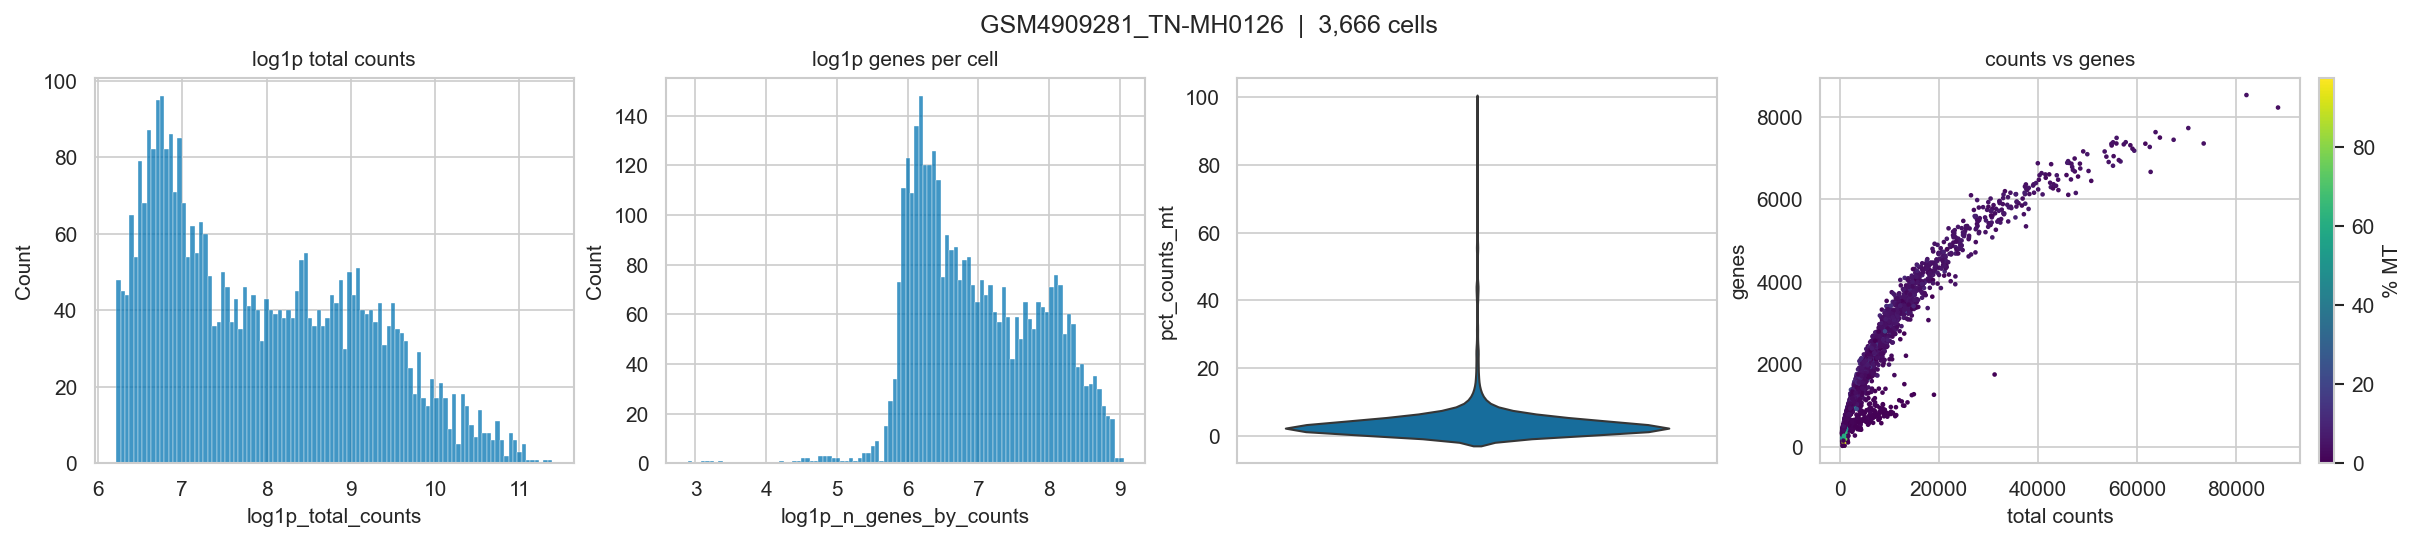

In [37]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), constrained_layout=True)
fig.suptitle(f"{sample_id}  |  {adata.n_obs:,} cells")
sns.histplot(adata.obs["log1p_total_counts"], bins=100, ax=axes[0])
axes[0].set_title("log1p total counts")
sns.histplot(adata.obs["log1p_n_genes_by_counts"], bins=100, ax=axes[1])
axes[1].set_title("log1p genes per cell")
sns.violinplot(y=adata.obs["pct_counts_mt"], ax=axes[2], inner=None)
axes[3].set_title("% mitochondrial")
sc_mt = axes[3].scatter(adata.obs["total_counts"], adata.obs["n_genes_by_counts"],
                      c=adata.obs["pct_counts_mt"], s=2, cmap="viridis", rasterized=True)
cbar = fig.colorbar(sc_mt, ax=axes[3], fraction=0.046, pad=0.04, aspect=25)
cbar.set_label("% MT")
axes[3].set(xlabel="total counts", ylabel="genes", title="counts vs genes")
plt.savefig(fig_dir / f"{sample_id}_qc_before.png", bbox_inches="tight")

plt.show()

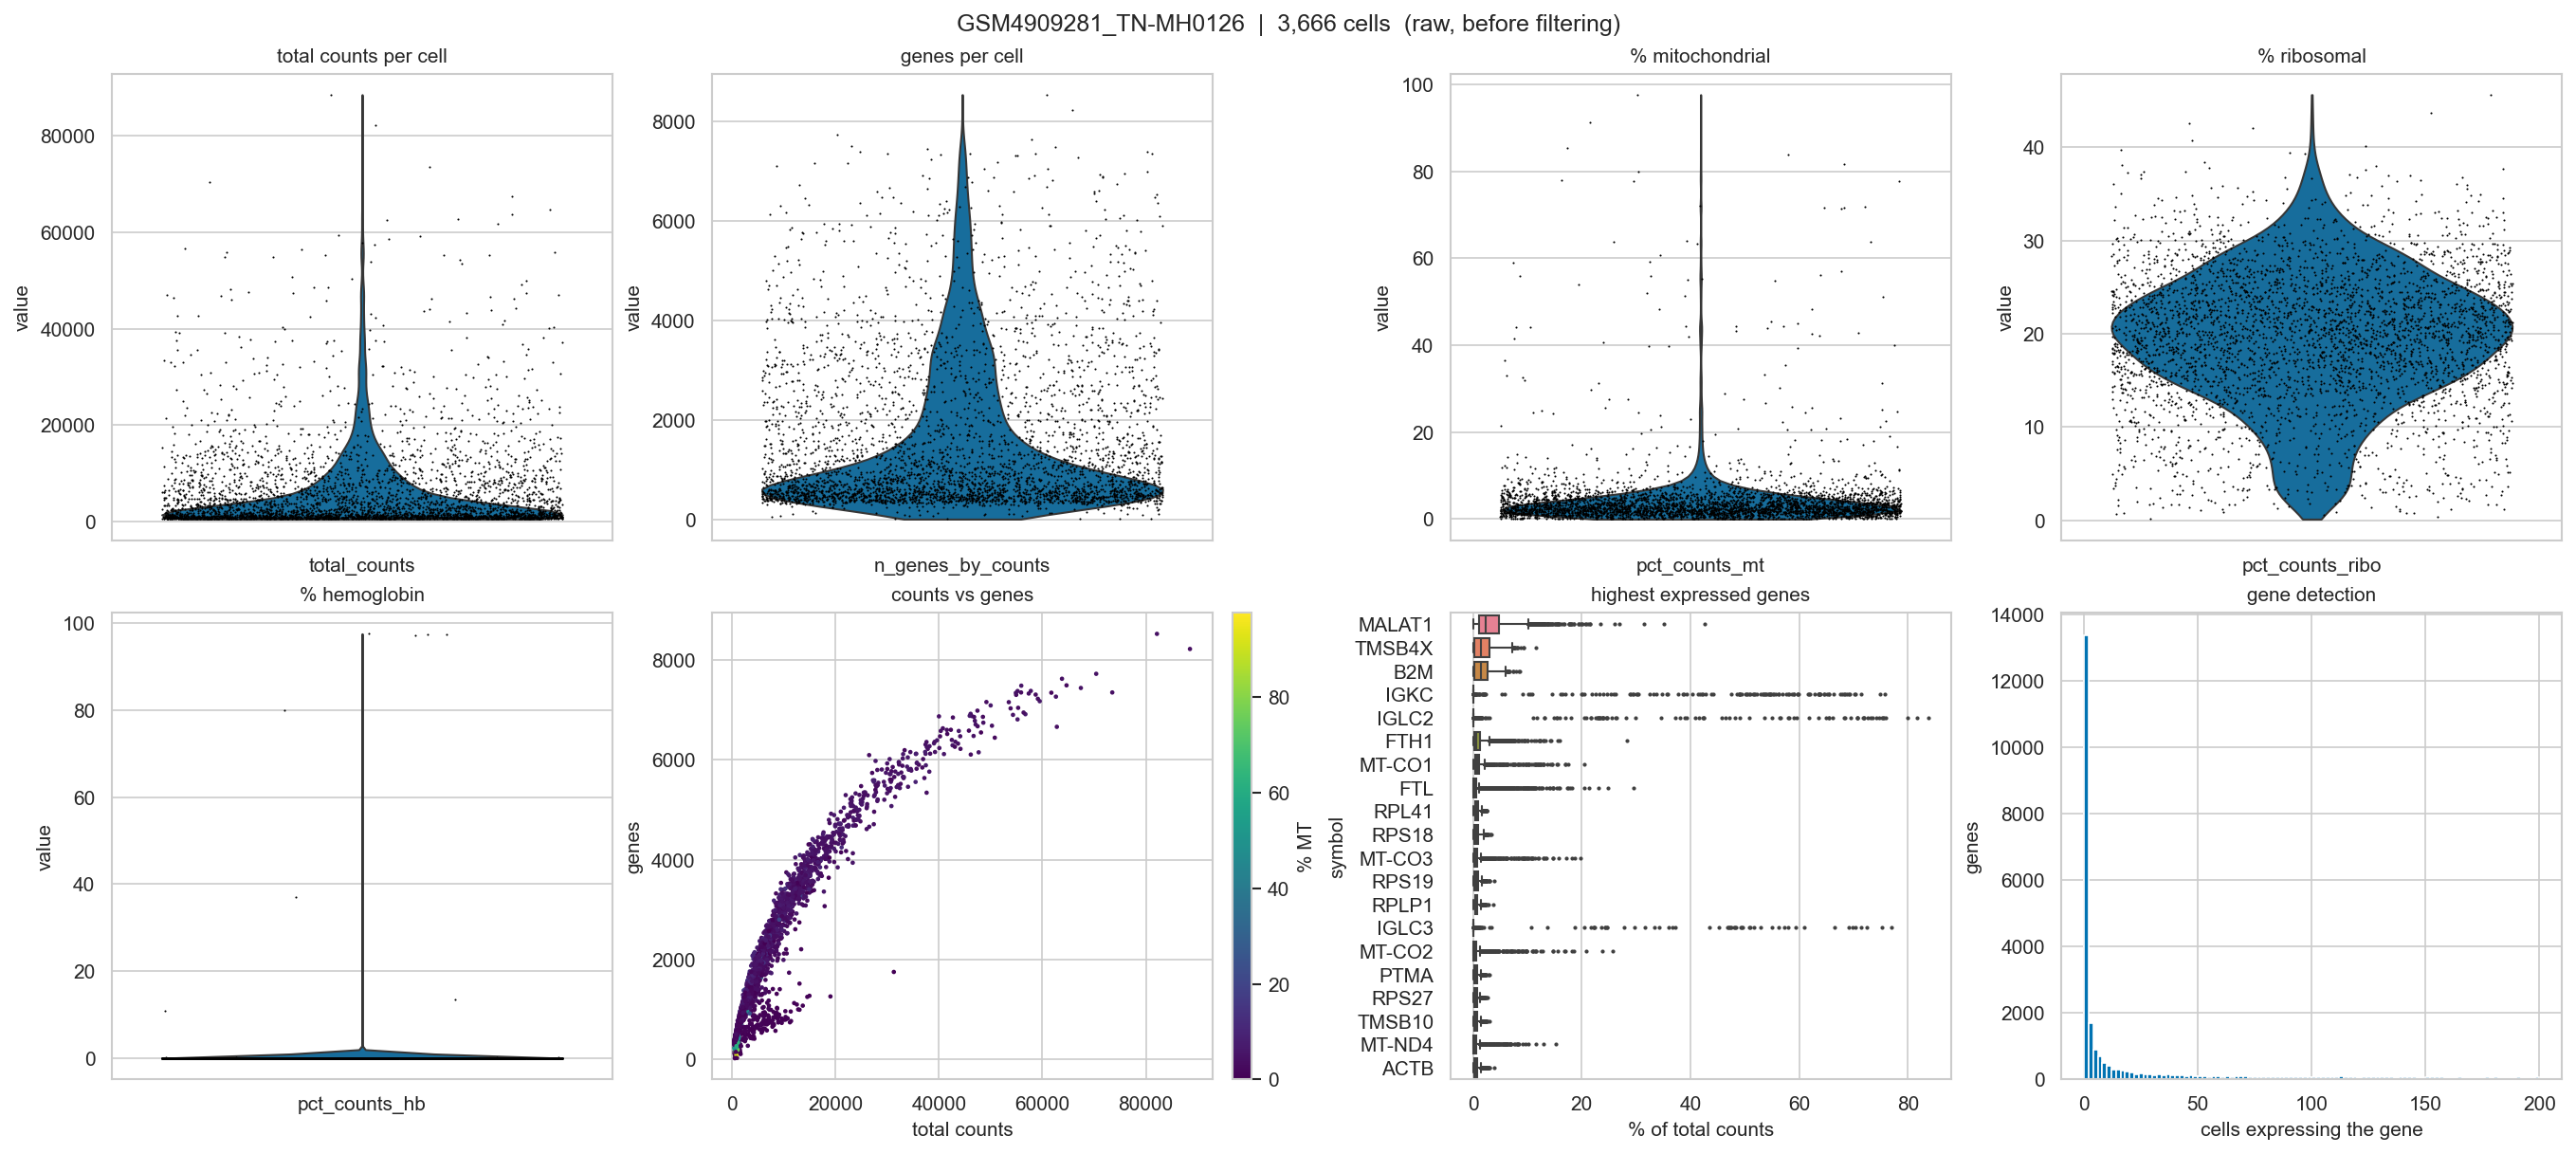

In [38]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8), constrained_layout=True)
fig.suptitle(f"{sample_id}  |  {adata.n_obs:,} cells  (raw, before filtering)")
ax = axes.ravel()
sc.pl.violin(adata, "total_counts", jitter=0.4, ax=ax[0], show=False)
ax[0].set_title("total counts per cell")
sc.pl.violin(adata, "n_genes_by_counts", jitter=0.4, ax=ax[1], show=False)
ax[1].set_title("genes per cell")
sc.pl.violin(adata, "pct_counts_mt", jitter=0.4, ax=ax[2], show=False)
ax[2].set_title("% mitochondrial")
sc.pl.violin(adata, "pct_counts_ribo", jitter=0.4, ax=ax[3], show=False)
ax[3].set_title("% ribosomal")
sc.pl.violin(adata, "pct_counts_hb", jitter=0.4, ax=ax[4], show=False)
ax[4].set_title("% hemoglobin")
sc_mt = ax[5].scatter(adata.obs["total_counts"], adata.obs["n_genes_by_counts"],
                      c=adata.obs["pct_counts_mt"], s=2, cmap="viridis", rasterized=True)
cbar = fig.colorbar(sc_mt, ax=ax[5], fraction=0.046, pad=0.04, aspect=25)
cbar.set_label("% MT")
ax[5].set(xlabel="total counts", ylabel="genes", title="counts vs genes")
sc.pl.highest_expr_genes(adata, n_top=20, ax=ax[6], show=False)
ax[6].set_title("highest expressed genes")
n_cells = np.asarray((adata.X > 0).sum(axis=0)).ravel()
ax[7].hist(n_cells, bins=100, range=(0, 200))
ax[7].set(xlabel="cells expressing the gene", ylabel="genes", title="gene detection")
plt.savefig(fig_dir / f"{sample_id}_qc_overview_raw.png", bbox_inches="tight")
plt.show()

In [39]:
# where the four target genes sit, before any filtering touches them
for g in ["ROR1", "ROR2", "EGFR", "ERBB2", "EPCAM"]:
    if g in adata.var_names:
        x = np.asarray(adata[:, g].X.todense()).ravel()
        print(f"{g:6s} detected in {(x > 0).sum():5d} / {adata.n_obs} cells "
              f"({100 * (x > 0).mean():5.2f}%)   max {int(x.max())} UMI")
    else:
        print(f"{g:6s} not in this sample")

ROR1   detected in    49 / 3666 cells ( 1.34%)   max 2 UMI
ROR2   detected in    32 / 3666 cells ( 0.87%)   max 2 UMI
EGFR   detected in   151 / 3666 cells ( 4.12%)   max 5 UMI
ERBB2  detected in   507 / 3666 cells (13.83%)   max 8 UMI
EPCAM  detected in  1150 / 3666 cells (31.37%)   max 107 UMI


## Filter cells 


In [40]:
%load_ext rpy2.ipython

In [41]:
with localconverter(ro.default_converter + numpy2ri.converter):
    ro.globalenv["mito"]  = adata.obs["pct_counts_mt"].to_numpy()
    ro.globalenv["ngene"] = adata.obs["n_genes_by_counts"].to_numpy().astype(float)

In [42]:
%%R
suppressMessages({library(miQC); library(SingleCellExperiment)})
sce <- SingleCellExperiment(assays = list(counts = matrix(0, nrow = 1, ncol = length(mito))))
colnames(sce) <- as.character(seq_along(mito))
sce$subsets_mito_percent <- mito
sce$detected <- ngene
set.seed(0)
model <- tryCatch(suppressWarnings(mixtureModel(sce)), error = function(e) NULL)
miqc_ok <- !is.null(model) && length(model@components) >= 2
kept <- if (miqc_ok) as.integer(colnames(filterCells(sce, model, verbose = FALSE))) else integer(0)

In [43]:
# On very clean samples the mixture collapses to one component and miQC cannot separate a compromised population. Fall back to a fixed threshold there, and record which samples fell back.
miqc_ok = bool(ro.globalenv["miqc_ok"][0])

In [44]:
if miqc_ok:
    miqc_keep = np.zeros(adata.n_obs, dtype=bool)
    miqc_keep[np.asarray(ro.globalenv["kept"]).astype(int) - 1] = True
else:
    print("miQC could not resolve two components - falling back to a fixed 20% threshold")
    miqc_keep = (adata.obs["pct_counts_mt"] <= 20).to_numpy()

A floor of 10% prevents over-filtering of clean samples, where the mixture otherwise splits the upper tail of a healthy distribution.

In [45]:
# On a clean sample miQC splits the upper tail of a healthy distribution and cuts at ~3.5% MT. Never call a cell compromised below this.
miqc_keep |= (adata.obs["pct_counts_mt"] < MT_FLOOR_PCT).to_numpy()

In [46]:
mt_filter_path = "miqc" if miqc_ok else "fixed_20pct"

In [47]:
keep = (
    (adata.obs["total_counts"] >= MIN_UMI).to_numpy()
    & (adata.obs["total_counts"] <= MAX_UMI).to_numpy()
    & (adata.obs["pct_counts_hb"] <= MAX_PCT_HB).to_numpy()
    & miqc_keep
)

In [48]:
adata.n_obs, keep.sum(), adata.obs['pct_counts_mt'][keep].max()

(3666, np.int64(3405), np.float32(9.959044))

In [49]:
adata = adata[keep].copy()

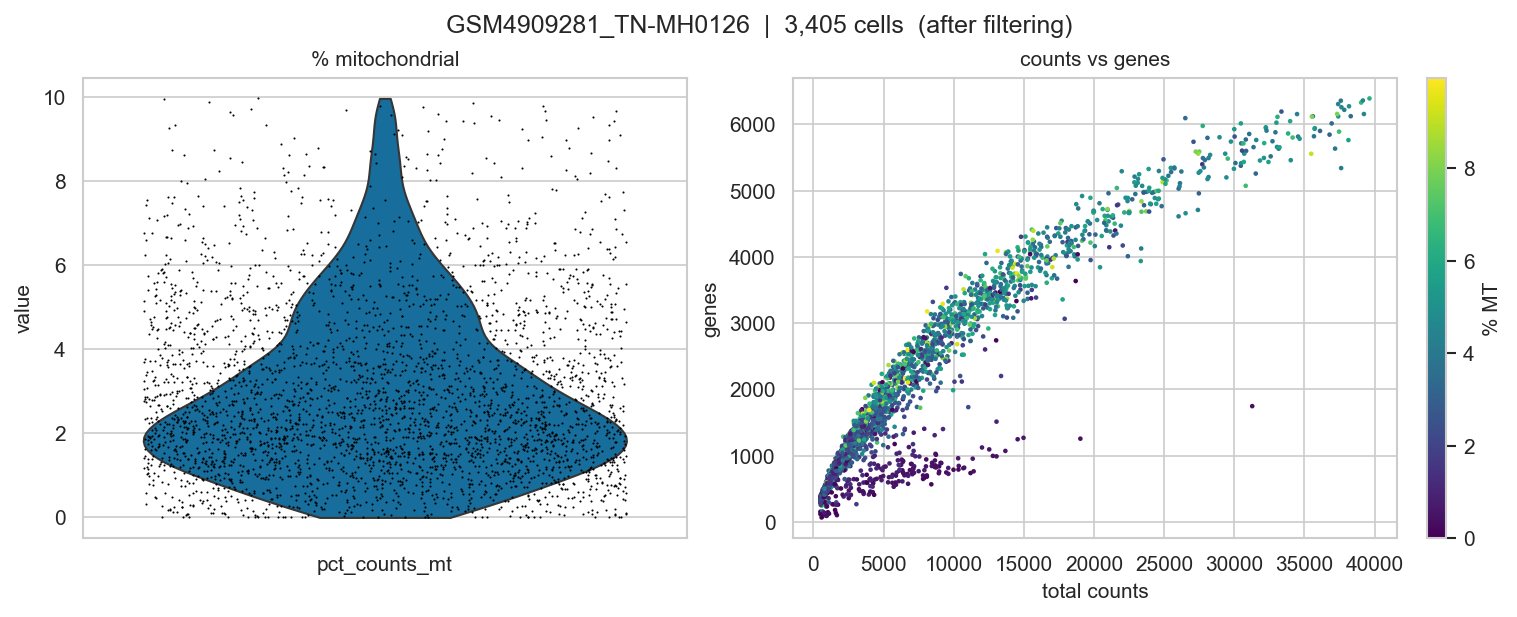

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
fig.suptitle(f"{sample_id}  |  {adata.n_obs:,} cells  (after filtering)")
sc.pl.violin(adata, "pct_counts_mt", jitter=0.4, ax=axes[0], show=False)
axes[0].set_title("% mitochondrial")
sc_mt = axes[1].scatter(adata.obs["total_counts"], adata.obs["n_genes_by_counts"],
                        c=adata.obs["pct_counts_mt"], s=2, cmap="viridis", rasterized=True)
cbar = fig.colorbar(sc_mt, ax=axes[1], fraction=0.046, pad=0.04, aspect=25)
cbar.set_label("% MT")
axes[1].set(xlabel="total counts", ylabel="genes", title="counts vs genes")

plt.savefig(fig_dir / f"{sample_id}_qc_after.png", bbox_inches="tight")
plt.show()

In [51]:
# No sc.pp.filter_genes

# Doublet removal with scDblFinder 

In [52]:
ro.globalenv["counts"] = to_r_sparse(adata.X.T)

In [53]:
%%R
 set.seed(0)
sce <- scDblFinder(SingleCellExperiment(list(counts = counts)))
doublet_class <- as.character(sce$scDblFinder.class)
doublet_score <- sce$scDblFinder.score

Creating ~2724 artificial doublets...
Dimensional reduction
Evaluating kNN...
Training model...
iter=0, 378 cells excluded from training.
iter=1, 426 cells excluded from training.
iter=2, 444 cells excluded from training.
Threshold found:0.683
211 (6.2%) doublets called


In [54]:
adata.obs["doublet_score"] = np.asarray(ro.globalenv["doublet_score"])

In [55]:
adata.obs["doublet_class"] = np.asarray(ro.globalenv["doublet_class"]).astype(str)

In [56]:
assert set(adata.obs["doublet_class"]) <= {"singlet", "doublet"}, \
    set(adata.obs["doublet_class"])

In [57]:
adata.obs["doublet_class"].value_counts().to_string()

'doublet_class\nsinglet    3194\ndoublet     211'

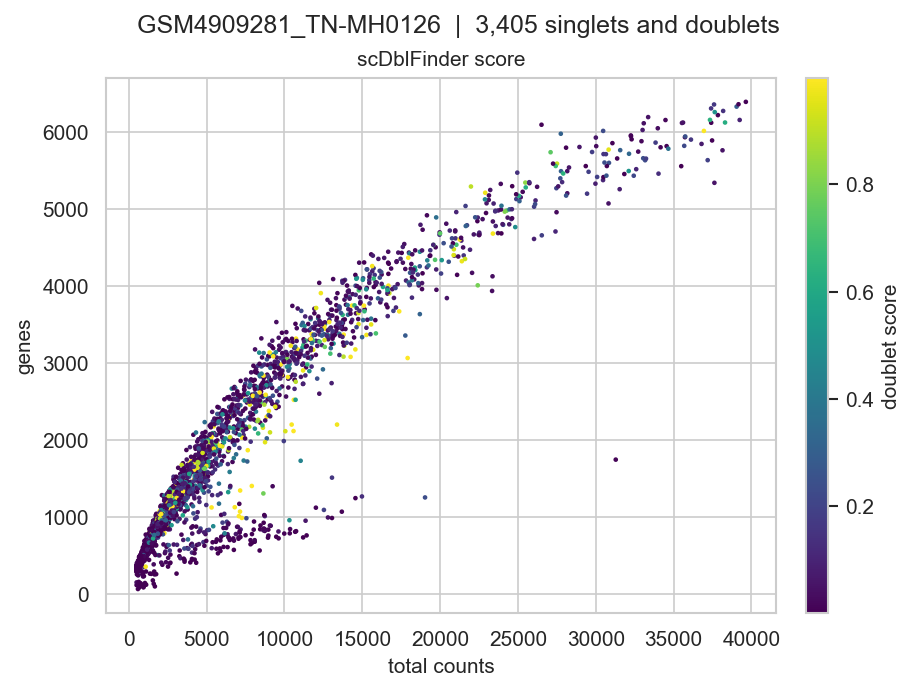

In [58]:
# doublet scores against depth and gene count
fig, ax = plt.subplots(figsize=(6, 4.5), constrained_layout=True)
fig.suptitle(f"{sample_id}  |  {adata.n_obs:,} singlets and doublets")

sc_db = ax.scatter(adata.obs["total_counts"], adata.obs["n_genes_by_counts"],
                   c=adata.obs["doublet_score"], s=2, cmap="viridis", rasterized=True)
cbar = fig.colorbar(sc_db, ax=ax, fraction=0.046, pad=0.04, aspect=25)
cbar.set_label("doublet score")
ax.set(xlabel="total counts", ylabel="genes", title="scDblFinder score")

plt.savefig(fig_dir / f"{sample_id}_doublets.png", bbox_inches="tight")
plt.show()

In [59]:
def pos(g):
    """Boolean mask of cells with g > 0; zeros if the gene is absent."""
    if g not in adata.var_names:
        return np.zeros(adata.n_obs, dtype=bool)
    return adata[:, g].X.toarray().ravel() > 0

In [60]:
dbl = (adata.obs["doublet_class"] == "doublet").to_numpy()

In [61]:
ror1_egfr_dp = pos("ROR1") & pos("EGFR")

In [62]:
epcam_erbb2_dp = pos("EPCAM") & pos("ERBB2")

In [63]:
for name, dp_mask in [("ROR1+EGFR", ror1_egfr_dp), ("EPCAM+ERBB2", epcam_erbb2_dp)]:
    if dp_mask.sum() == 0:
        print(f"{name}: none in this sample")
        continue
    print(f"{name}: {dp_mask.sum()} double positive, "
          f"{100 * dbl[dp_mask].mean():.0f}% of them are doublets "
          f"(background {100 * dbl.mean():.1f}%)")

ROR1+EGFR: 7 double positive, 0% of them are doublets (background 6.2%)
EPCAM+ERBB2: 384 double positive, 6% of them are doublets (background 6.2%)


In [64]:
n_before_doublets = adata.n_obs

In [65]:
n_doublets = int((adata.obs["doublet_class"] == "doublet").sum())
print(adata.obs["doublet_class"].value_counts().to_string())

doublet_class
singlet    3194
doublet     211


In [66]:
adata = adata[adata.obs["doublet_class"] == "singlet"].copy()

In [67]:
adata.n_obs, n_doublets, 100 * n_doublets / n_before_doublets

(3194, 211, 6.196769456681351)

In [68]:
# normalise, keep raw counts 

In [69]:
adata.layers["counts"] = adata.X.copy()

In [70]:
sc.pp.normalize_total(adata, target_sum=1e4)

In [71]:
sc.pp.log1p(adata)

In [72]:
adata.layers["log1p"] = adata.X.copy()

# feature selection with scry

In [73]:
ro.globalenv["counts"] = to_r_sparse(adata.layers["counts"].T)

In [74]:
%%R
sce <- SingleCellExperiment(list(counts = counts))
sce <- devianceFeatureSelection(sce)
deviance <- rowData(sce)$binomial_deviance

In [75]:
adata.var["deviance"] = np.asarray(ro.globalenv["deviance"])

In [76]:
exclude = adata.var[["mt", "ribo", "hb"]].any(axis=1).to_numpy()

In [77]:
exclude |= adata.var_names.isin(s_genes + g2m_genes)

In [78]:
order = np.argsort(adata.var["deviance"].to_numpy())[::-1]

In [79]:
top = order[~exclude[order]][:N_HVG]
adata.var["highly_variable"] = False
adata.var.iloc[top, adata.var.columns.get_loc("highly_variable")] = True

In [80]:
adata.var["highly_variable"].sum()

np.int64(2000)

In [81]:
mean_expr = np.asarray(adata.layers["counts"].mean(axis=0)).ravel()

In [82]:
hv = adata.var["highly_variable"].to_numpy()

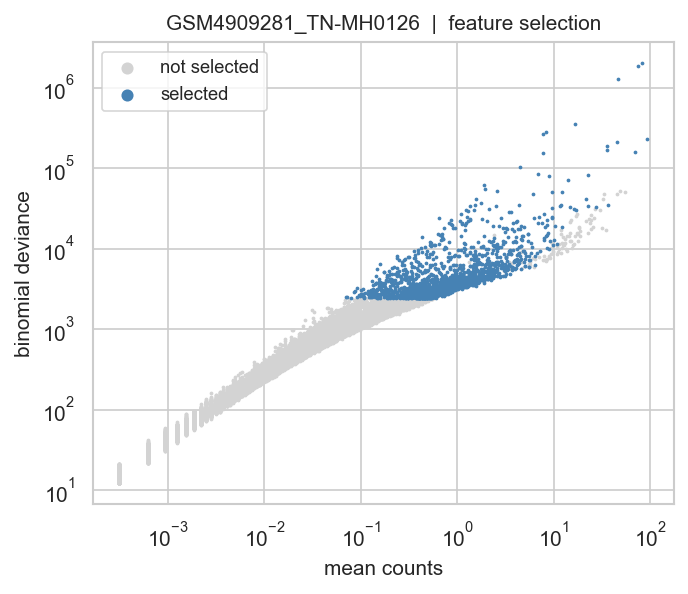

In [83]:
plt.figure(figsize=(5, 4))
plt.scatter(mean_expr[~hv], adata.var["deviance"][~hv], s=1, c="lightgrey", label="not selected")
plt.scatter(mean_expr[hv],  adata.var["deviance"][hv],  s=1, c="steelblue", label="selected")
plt.xscale("log"); plt.yscale("log")
plt.xlabel("mean counts"); plt.ylabel("binomial deviance")
plt.title(f"{sample_id}  |  feature selection")
plt.legend(markerscale=5)
plt.savefig(fig_dir / f"{sample_id}_deviance.png", bbox_inches="tight")
plt.show()

# PCA and depth check

In [84]:
sc.pp.pca(adata, n_comps=50, mask_var="highly_variable")

In [85]:
r = np.corrcoef(adata.obsm["X_pca"][:, 0], adata.obs["total_counts"])[0, 1]

In [86]:
r

np.float64(0.7602370343847334)

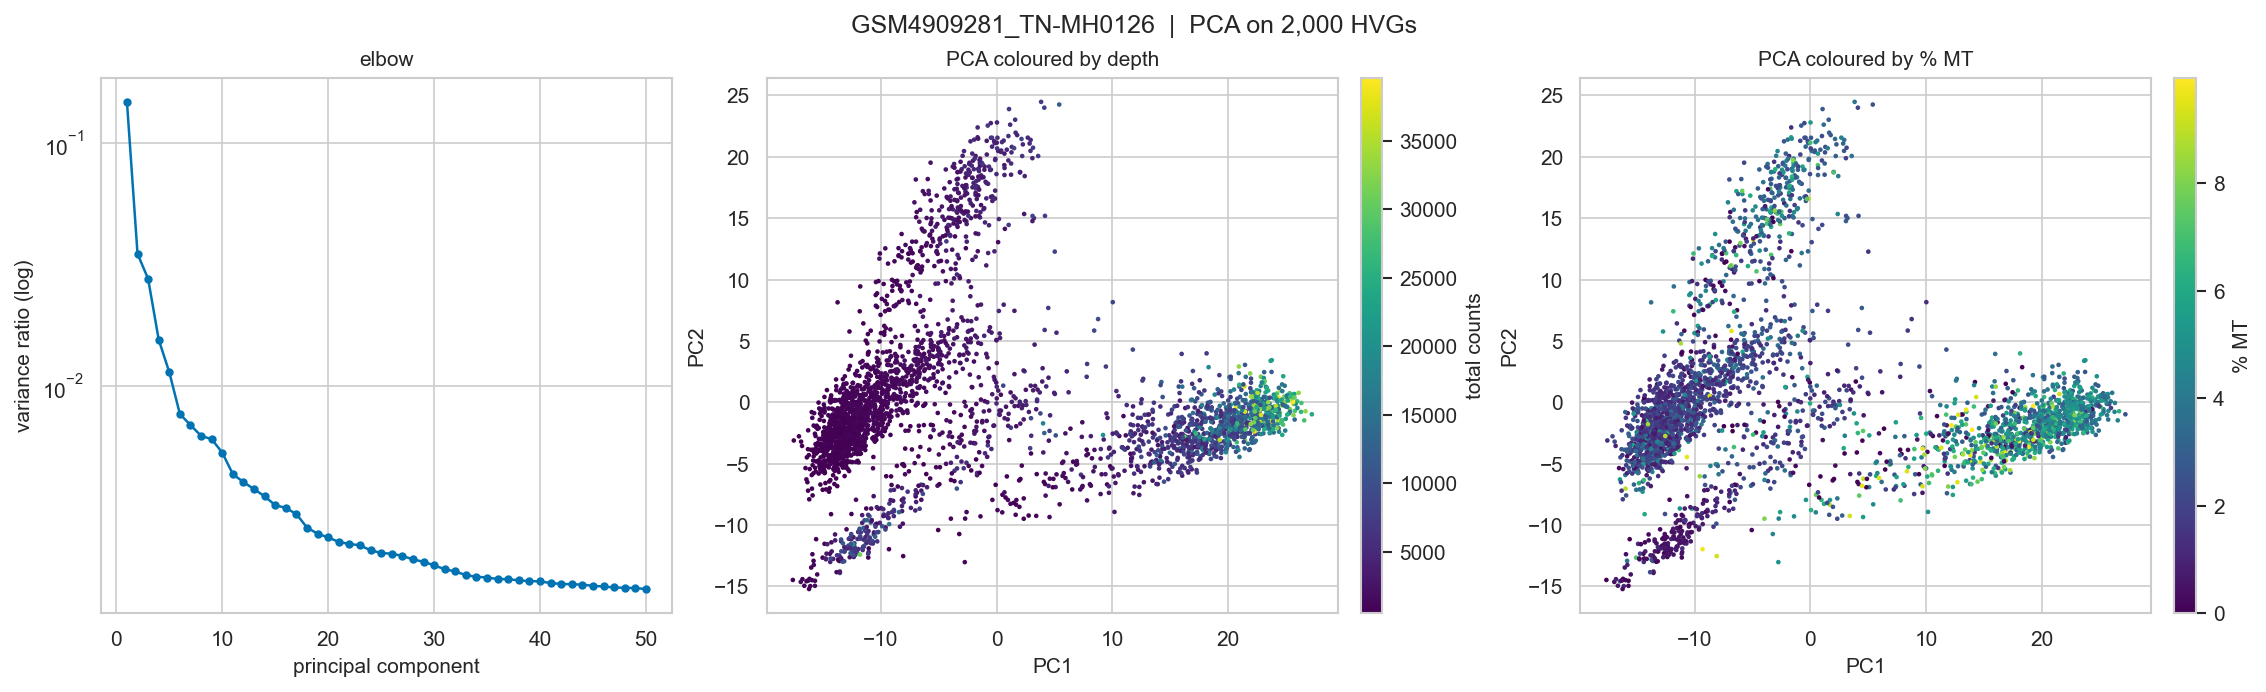

In [87]:
# PCA diagnostics: 1 x 3 panels
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), constrained_layout=True)
fig.suptitle(f"{sample_id}  |  PCA on {adata.var['highly_variable'].sum():,} HVGs")
var_ratio = adata.uns["pca"]["variance_ratio"][:50]
axes[0].plot(np.arange(1, len(var_ratio) + 1), var_ratio, "o-", ms=3)
axes[0].set_yscale("log")
axes[0].set(xlabel="principal component", ylabel="variance ratio (log)", title="elbow")
pcs = adata.obsm["X_pca"]
for ax, key, label, title in [
    (axes[1], "total_counts", "total counts", "PCA coloured by depth"),
    (axes[2], "pct_counts_mt", "% MT", "PCA coloured by % MT"),
]:
    sc_pc = ax.scatter(pcs[:, 0], pcs[:, 1], c=adata.obs[key], s=2,
                       cmap="viridis", rasterized=True)
    cbar = fig.colorbar(sc_pc, ax=ax, fraction=0.046, pad=0.04, aspect=25)
    cbar.set_label(label)
    ax.set(xlabel="PC1", ylabel="PC2", title=title)

plt.savefig(fig_dir / f"{sample_id}_pca_qc.png", bbox_inches="tight")
plt.show()

# save object

In [88]:
adata.X = adata.layers["counts"].copy()

In [89]:
adata.write_h5ad(head_dir / f"{sample_id}.h5ad")

In [90]:
adata

AnnData object with n_obs × n_vars = 3194 × 33538
    obs: 'sample', 'condition', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'S_score', 'G2M_score', 'phase', 'doublet_score', 'doublet_class'
    var: 'gene_id', 'feature_type', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'deviance', 'highly_variable'
    uns: 'log1p', 'pca'
    obsm: 'X_pca'
    varm: 'PCs'
    layers: 'counts', 'log1p'

In [92]:
# One row per sample. papermill.ipynb concatenates all 45 into the supplementary QC table.
pd.DataFrame([{
    "sample":          sample_id,
    "condition":       str(adata.obs["condition"].iloc[0]),
    "n_cells_final":   adata.n_obs,
    "n_genes":         adata.n_vars,
    "max_pct_mt_retained": round(float(adata.obs["pct_counts_mt"].max()), 1),
    "pct_doublets":    round(100 * n_doublets / n_before_doublets, 1),
    "pc1_depth_corr":  round(float(r), 3),
    "median_counts":   int(adata.obs["total_counts"].median()),
    "median_genes":    int(adata.obs["n_genes_by_counts"].median()),
    "ror1_egfr_dp": int(ror1_egfr_dp.sum()),
    "ror1_egfr_dp_doublet_pct": round(100 * dbl[ror1_egfr_dp].mean(), 1) if ror1_egfr_dp.any() else np.nan,
    "epcam_erbb2_dp": int(epcam_erbb2_dp.sum()),
    "epcam_erbb2_dp_doublet_pct": round(100 * dbl[epcam_erbb2_dp].mean(), 1) if epcam_erbb2_dp.any() else np.nan,
    "miqc_converged": miqc_ok,
    "mt_filter_path": mt_filter_path,
    "mt_floor": MT_FLOOR_PCT,
}]).to_csv(df_dir / f"qc_{sample_id}.csv", index=False)

In [93]:
f"qc_{sample_id}.csv"

'qc_GSM4909281_TN-MH0126.csv'

In [ ]:
# run papermill on this notebook for each patient in the list of samples to generate a separate h5ad file for each patient

In [94]:
import session_info
session_info.show()

/Users/gernotstuhler/miniforge3_arm64/envs/conda_py312/lib/python3.12/site-packages/session_info/main.py:213: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  mod_version = _find_version(mod.__version__)
/Users/gernotstuhler/miniforge3_arm64/envs/conda_py312/lib/python3.12/site-packages/session_info/main.py:213: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  mod_version = _find_version(mod.__version__)
